# Two-mode squeezing

Simulação da evolução de dois modos sob uma Hamiltoniana de squeezing, sem operadores de dissipação no solucionador. Requer QuTiP, NumPy e Matplotlib. Execute as células em ordem.

Quantum object: dims=[[30, 30], [1]], shape=(900, 1), type='ket', dtype=Dense
Qobj data =
[[ 0.1627258 ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.16418844]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.        ]
 [ 0.     

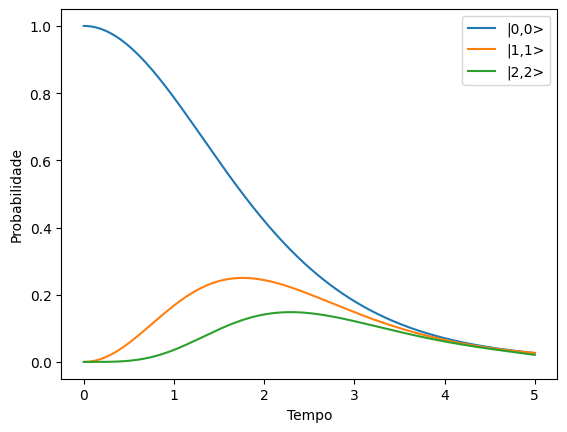

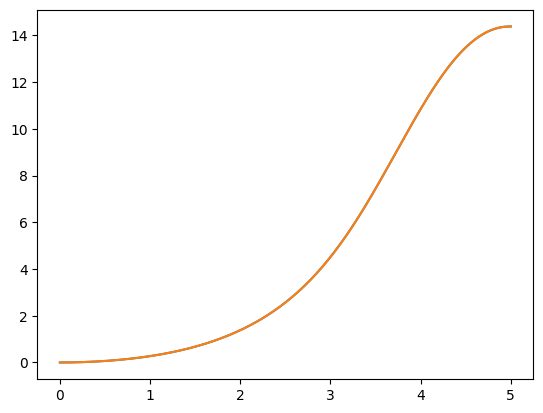

In [2]:
!pip install qutip
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image
from qutip import (about, destroy, hinton, ptrace, qdiags, qeye, steadystate,
                   tensor, wigner, wigner_cmap, basis, fidelity, mesolve, expect)

%matplotlib inline

# Simular squeezing de dois modos sem operadores de dissipação.

#Parâmetros

wo = 1.0 * 2 * np.pi #frequência da cavidade óptica
wm = 1.0 * 2 * np.pi # frequência da cavidade mecânica
g = 0.005 * 2 * np.pi #constante de acoplamento entre cavidades
No = 30 # número de cavidades ópticas no estado de fock
Nm = 30 # número de cavidades mecânicas no estado de fock
r = 0.5
phi = 0.0

kappa = r * np.exp(1j * phi) #patâmetro squeezing

#Definir Operadores para a Hamiltoniana

a = tensor(destroy(No), qeye(Nm))
b = tensor(qeye(No), destroy(Nm))
num_b = b.dag() * b
num_a = a.dag() * a

#HAMILTONIANA

H = 1j * kappa * (a.dag() * b.dag() - a * b)

# Criar um quantoum de excitação

psi = tensor(basis(No,0),basis(Nm,0))

# Evolução Temporal

tlist = np.linspace(0,5,300)

output = mesolve(H,psi, tlist,[],[])

# Escrever o Estado evouído
print(output.states[-1])
print(f"Dimensões: {output.states[-1].dims}")

#Probabilidade
proj_00 = tensor(basis(No,0), basis(Nm,0))
proj_11 = tensor(basis(No,1), basis(Nm,1))
proj_22 = tensor(basis(No,2), basis(Nm,2))

P00 = expect(proj_00*proj_00.dag(), output.states)
P11 = expect(proj_11*proj_11.dag(), output.states)
P22 = expect(proj_22*proj_22.dag(), output.states)


#Plotar gráfico de probabilidade x tempo, isso vai mostrar graficamente o que são as oscilações de Rabi (vão ser funções de seno e cosseno)

plt.plot(tlist, P00, label="|0,0>")
plt.plot(tlist, P11, label="|1,1>")
plt.plot(tlist, P22, label="|2,2>")
plt.xlabel("Tempo")
plt.ylabel("Probabilidade")
plt.legend()
plt.show()

na = expect(num_a, output.states)
nb = expect(num_b, output.states)

plt.plot(tlist, na)
plt.plot(tlist, nb)
plt.show()

